## Lead localization

In [14]:
import os
import cv2
import torch
import shutil
from tqdm import tqdm
from ultralytics import YOLO
import random
import numpy as np
import PIL.Image as Image
import PIL.ImageEnhance as ImageEnhance

In [56]:
model_path = "" # Fill with your own path
input_folder = "" # Fill with your own path
output_folder = "" # Fill with your own path

normal_folder = os.path.join(output_folder, "normal")
overlap_folder = os.path.join(output_folder, "overlap")
os.makedirs(normal_folder, exist_ok=True)
os.makedirs(overlap_folder, exist_ok=True)
os.makedirs(output_folder, exist_ok=True)

device = "cuda" if torch.cuda.is_available() else "cpu"
model = YOLO(model_path)
model.to(device)

bbox_csv_path = os.path.join(output_folder, "bbox_cropped_overlap.csv")
overlap_csv_path = os.path.join(output_folder, "overlap_metadata.csv")

In [57]:
def degrade_ecg_image(img):
    """
    img: numpy.ndarray (BGR, uint8)
    """
    img = img.copy()

    if random.random() < 0.5:
        noise = np.random.normal(0, 25, img.shape).astype(np.int16)
        img = np.clip(img.astype(np.int16) + noise, 0, 255).astype(np.uint8)

    if random.random() < 0.3:
        k = random.choice([3, 5])
        img = cv2.GaussianBlur(img, (k, k), 0)

    if random.random() < 0.3:
        for _ in range(random.randint(1, 3)):
            center = (
                random.randint(0, img.shape[1] - 1),
                random.randint(0, img.shape[0] - 1),
            )
            radius = random.randint(3, 10)
            color = random.choice([(100, 100, 100), (200, 200, 200)])
            cv2.circle(img, center, radius, color, -1)

    if random.random() < 0.7:
        pil_img = Image.fromarray(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        pil_img = ImageEnhance.Brightness(pil_img).enhance(random.uniform(0.7, 1.3))
        pil_img = ImageEnhance.Contrast(pil_img).enhance(random.uniform(0.7, 1.3))
        img = cv2.cvtColor(np.array(pil_img), cv2.COLOR_RGB2BGR)

    return img

In [58]:
if not os.path.exists(bbox_csv_path):
    with open(bbox_csv_path, "w") as f:
        f.write(
            "filename,index,label,conf,x1,y1,x2,y2,"
            "crop_w,crop_h,w_orig,h_orig,"
            "bbox_center_x,bbox_center_y\n"
        )

if not os.path.exists(overlap_csv_path):
    with open(overlap_csv_path, "w") as f:
        f.write(
            "filename,lead1_idx,lead2_idx,lead1_label,lead2_label,"
            "overlap_x1,overlap_y1,overlap_x2,overlap_y2,"
            "overlap_area,overlap_w,overlap_h,iou,"
            "lead1_area,lead2_area\n"
        )

In [59]:
def calculate_iou(box1, box2):
    x1_1, y1_1, x2_1, y2_1 = box1
    x1_2, y1_2, x2_2, y2_2 = box2

    x1_i = max(x1_1, x1_2)
    y1_i = max(y1_1, y1_2)
    x2_i = min(x2_1, x2_2)
    y2_i = min(y2_1, y2_2)

    if x2_i <= x1_i or y2_i <= y1_i:
        return None

    overlap_area = (x2_i - x1_i) * (y2_i - y1_i)
    area1 = (x2_1 - x1_1) * (y2_1 - y1_1)
    area2 = (x2_2 - x1_2) * (y2_2 - y1_2)

    iou = overlap_area / (area1 + area2 - overlap_area)

    return {
        "x1": x1_i, "y1": y1_i, "x2": x2_i, "y2": y2_i,
        "overlap_area": overlap_area,
        "overlap_w": x2_i - x1_i,
        "overlap_h": y2_i - y1_i,
        "iou": iou,
        "area1": area1,
        "area2": area2
    }

In [60]:
def visualize_with_overlap(img, lead_boxes, filename, save_dir):
    vis = img.copy()

    # Draw boxes
    for lead in lead_boxes.values():
        x1, y1, x2, y2 = lead["bbox"]
        cv2.rectangle(vis, (x1, y1), (x2, y2), (0, 255, 0), 2)

    # Draw overlaps
    lead_indices = list(lead_boxes.keys())
    for i in range(len(lead_indices)):
        for j in range(i + 1, len(lead_indices)):
            overlap = calculate_iou(
                lead_boxes[lead_indices[i]]["bbox"],
                lead_boxes[lead_indices[j]]["bbox"]
            )
            if overlap:
                cv2.rectangle(
                    vis,
                    (overlap["x1"], overlap["y1"]),
                    (overlap["x2"], overlap["y2"]),
                    (0, 0, 255),
                    2
                )

    os.makedirs(save_dir, exist_ok=True)
    cv2.imwrite(os.path.join(save_dir, filename), vis)


In [61]:
image_files = [f for f in os.listdir(input_folder) if f.lower().endswith(".jpg")]

for filename in tqdm(image_files, desc="Processing images"):
    image_path = os.path.join(input_folder, filename)
    img = cv2.imread(image_path)
    # img = degrade_ecg_image(img)
    if img is None:
        raise FileNotFoundError(f"Cannot read image: {image_path}")

    h_orig, w_orig = img.shape[:2]

    results = model(
        img,
        conf=0.25,
        imgsz=640,
        device=device,
        verbose=False
    )

    class_detections = {}

    for box in results[0].boxes:
        cls = int(box.cls[0])
        conf = float(box.conf[0])

        if cls not in class_detections or conf > class_detections[cls]["conf"]:
            class_detections[cls] = {
                "conf": conf,
                "box": box,
                "label": results[0].names[cls]
            }

    lead_boxes = {}

    for cls, detection in class_detections.items():
        box = detection["box"]
        label = detection["label"]
        conf = detection["conf"]

        x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())

        # scale_x = w_orig / 640
        # scale_y = h_orig / 640
        # x1 = int(x1 * scale_x)
        # y1 = int(y1 * scale_y)
        # x2 = int(x2 * scale_x)
        # y2 = int(y2 * scale_y)

        x1, y1 = max(0, x1), max(0, y1)
        x2, y2 = min(w_orig, x2), min(h_orig, y2)

        crop_w, crop_h = x2 - x1, y2 - y1
        bbox_center_x = (x1 + x2) / 2
        bbox_center_y = (y1 + y2) / 2

        lead_boxes[cls] = {
            "bbox": (x1, y1, x2, y2),
            "label": label,
            "index": cls,
            "conf": conf,
            "crop_w": crop_w,
            "crop_h": crop_h,
            "bbox_center_x": bbox_center_x,
            "bbox_center_y": bbox_center_y
        }

        # cropped = img[y1:y2, x1:x2]
        # save_path = os.path.join(
        #     output_folder,
        #     f"{os.path.splitext(filename)[0]}_{cls:02d}_{label}.jpg"
        # )
        # cv2.imwrite(save_path, cropped)

        # with open(bbox_csv_path, "a") as f:
        #     f.write(
        #         f"{filename},{cls},{label},{conf:.4f},"
        #         f"{x1},{y1},{x2},{y2},"
        #         f"{crop_w},{crop_h},{w_orig},{h_orig},"
        #         f"{bbox_center_x:.2f},{bbox_center_y:.2f}\n"
        #     )

    overlapping_leads = set()
    lead_indices = list(lead_boxes.keys())
    for i in range(len(lead_indices)):
        for j in range(i + 1, len(lead_indices)):
            lead1 = lead_boxes[lead_indices[i]]
            lead2 = lead_boxes[lead_indices[j]]

            overlap = calculate_iou(lead1["bbox"], lead2["bbox"])
            if overlap:
                overlapping_leads.add(lead_indices[i])
                overlapping_leads.add(lead_indices[j])
                with open(overlap_csv_path, "a") as f:
                    f.write(
                        f"{filename},{lead1['index']},{lead2['index']},"
                        f"{lead1['label']},{lead2['label']},"
                        f"{overlap['x1']},{overlap['y1']},"
                        f"{overlap['x2']},{overlap['y2']},"
                        f"{overlap['overlap_area']},"
                        f"{overlap['overlap_w']},{overlap['overlap_h']},"
                        f"{overlap['iou']:.4f},"
                        f"{overlap['area1']},{overlap['area2']}\n"
                    )
    for cls, lead_data in lead_boxes.items():
        x1, y1, x2, y2 = lead_data["bbox"]
        label = lead_data["label"]
        conf = lead_data["conf"]
        
        cropped = img[y1:y2+3, x1:x2]
        
        # Determine which folder to save to
        has_overlap = cls in overlapping_leads
        target_folder = overlap_folder if has_overlap else normal_folder
        
        save_path = os.path.join(
            target_folder,
            f"{os.path.splitext(filename)[0]}_{cls:02d}_{label}.jpg"
        )
        cv2.imwrite(save_path, cropped)

        # Write to CSV with overlap flag
        with open(bbox_csv_path, "a") as f:
            f.write(
                f"{filename},{cls},{label},{conf:.4f},"
                f"{x1},{y1},{x2},{y2},"
                f"{lead_data['crop_w']},{lead_data['crop_h']},{w_orig},{h_orig},"
                f"{lead_data['bbox_center_x']:.2f},{lead_data['bbox_center_y']:.2f},"
                f"{has_overlap}\n"
            )

    visualize_with_overlap(
        img, lead_boxes, filename,
        os.path.join(output_folder, "visualizations")
    )
print("\ncomplete")


Processing images: 100%|██████████| 2884/2884 [05:03<00:00,  9.50it/s]


complete


## U-Net Segmentation

In [62]:
import segmentation_models_pytorch as smp
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = smp.Unet(
    encoder_name="resnet34",       
    encoder_weights=None,  
    in_channels=3,                 
    classes=1,                     
)

checkpoint = torch.load(
    "", # Fill with your own path
    map_location=device
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()


Unet(
  (encoder): ResNetEncoder(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track

In [63]:
cropped_normal= "" # Fill with your own path
output_segmentation_normal = "" # Fill with your own path
cropped_overlap = "" # Fill with your own path
output_segmentation_overlap = "" # Fill with your own path

os.makedirs(os.path.join(output_segmentation_normal, "masks"), exist_ok=True)
os.makedirs(os.path.join(output_segmentation_normal, "overlays"), exist_ok=True)
os.makedirs(os.path.join(output_segmentation_overlap, "masks"), exist_ok=True)
os.makedirs(os.path.join(output_segmentation_overlap, "overlays"), exist_ok=True)

In [64]:
def preprocess_image(image):
    """
    Same preprocessing as your ECGDataset (without augmentation)
    Returns: tensor, original_h, original_w
    """
    # Convert to RGB
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    
    # Normalize
    image = image.astype(np.float32)
    
    # Get original size
    h, w = image.shape[:2]
    
    # Pad to multiple of 16
    H_pad = ((h + 15) // 16) * 16
    W_pad = ((w + 15) // 16) * 16
    pad_h = H_pad - h
    pad_w = W_pad - w
    
    image = np.pad(image, ((0, pad_h), (0, pad_w), (0, 0)), mode='constant')
    
    # To tensor
    image = torch.tensor(image, dtype=torch.float32).permute(2,0,1).unsqueeze(0)
    
    return image, h, w

In [65]:
def segment_ecg(image_path, model, device):
    """
    Run U-Net segmentation on a single image
    Returns: binary mask (original size), confidence mask (original size)
    """
    # Load image
    img = cv2.imread(image_path)
    if img is None:
        raise FileNotFoundError(f"Cannot read: {image_path}")
    
    # Preprocess
    img_tensor, orig_h, orig_w = preprocess_image(img)
    img_tensor = img_tensor.to(device)  # Add batch dimension
    
    # Inference
    with torch.no_grad():
        output = model(img_tensor)
        output = torch.sigmoid(output)  # Get probabilities [0, 1]
    
    # Post-process
    mask_prob = output.squeeze().cpu().numpy()  # Remove batch & channel dims
    
    # Crop back to original size (remove padding)
    mask_binary = mask_prob[:orig_h, :orig_w]
    # print(mask_prob)
    # Binary mask (threshold at 0.5)
    mask_binary = (mask_binary > 0.5).astype(np.uint8)*255
    
    # Confidence mask (0-255 scale)
    mask_conf = (mask_binary * 255).astype(np.uint8)
    
    return mask_binary, mask_conf, img

In [67]:
def process_folder(input_folder, output_base, model, device):
    """
    Process all images in a folder
    """
    image_files = [f for f in os.listdir(input_folder) if f.lower().endswith(".jpg")]

    mask_dir = os.path.join(output_base, "masks")
    overlay_dir = os.path.join(output_base, "overlays")

    os.makedirs(mask_dir, exist_ok=True)
    os.makedirs(overlay_dir, exist_ok=True)
    
    for filename in tqdm(image_files):
        img_path = os.path.join(input_folder, filename)
        
        mask_path = os.path.join(mask_dir, f"mask_{filename}")
        overlay_path = os.path.join(overlay_dir, f"overlay_{filename}")

        if os.path.exists(mask_path) and os.path.exists(overlay_path):
            continue
        
        try:
            # Run segmentation
            mask_binary, mask_conf, original_img = segment_ecg(img_path, model, device)
            # mask_binary = thin_mask(mask_binary)
            # Save binary mask
            mask_path = os.path.join(output_base, "masks", f"mask_{filename}")
            
            cv2.imwrite(mask_path, mask_binary)
            
            overlay = cv2.imread(img_path)
            overlay = cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB)
            # white_bg = np.ones_like(overlay, dtype=np.uint8) * 255
            # Red overlay on detected signal
            red_mask = np.zeros_like(overlay)
            red_mask[:, :, 0] = mask_binary  # Red channel
            overlay = cv2.addWeighted(overlay, 0.7, red_mask, 1, 0)
            overlay = cv2.cvtColor(overlay, cv2.COLOR_RGB2BGR)
            
            overlay_path = os.path.join(output_base, "overlays", f"overlay_{filename}")
            cv2.imwrite(overlay_path, overlay)
            
        except Exception as e:
            print(f"Error processing {filename}: {e}")

print("Processing normal")
process_folder(cropped_normal, output_segmentation_normal, model, device)

print("\nProcessing overlap")
process_folder(cropped_overlap, output_segmentation_overlap, model, device)

print("\ncomplete")

Processing normal


  0%|          | 0/26533 [00:00<?, ?it/s]

100%|██████████| 26533/26533 [26:19<00:00, 16.80it/s]



Processing overlap


100%|██████████| 10925/10925 [11:15<00:00, 16.18it/s]


complete


## Signal Extraction

### Try per image

#### extract signal

In [15]:
import os
input_folder = "" # Fill with your own path
filename = "mask_18576_08_V3.jpg" 
img_path = os.path.join(input_folder, filename)
img_mask = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)

In [16]:
from skimage.morphology import skeletonize
def extract_ecg(mask):
    mask_bin = (mask > 127).astype(np.uint8)
    skel = skeletonize(mask_bin).astype(np.uint8)
    ys, xs = np.where(skel == 1)
    points = np.column_stack((xs, ys))

    idx = np.argsort(points[:,0])
    return points[idx]

In [ ]:
import cv2
print(f"image shape: {img_mask.shape}")
if img_mask.ndim == 3:
    img_mask = img_mask[:, :, 0]
predicted_raw = extract_ecg(img_mask)

predicted_pts = predicted_raw.reshape(-1, 2)
print(f"predicted pts: {len(predicted_pts)}") #334
    
predicted_x = predicted_pts[:, 0].astype(np.float32)
predicted_y = predicted_pts[:, 1].astype(np.float32)

mask = np.isfinite(predicted_x) & np.isfinite(predicted_y)
predicted_x_clean = predicted_x[mask]
predicted_y_clean = predicted_y[mask]
print(len(predicted_x_clean)) #334
print(len(predicted_y_clean))
    
sort_idx = np.argsort(predicted_x_clean)
predicted_x_clean = predicted_x_clean[sort_idx]
predicted_y_clean = predicted_y_clean[sort_idx]
    
xs = predicted_x_clean
ys = predicted_y_clean

x_unique = np.unique(xs)
y_center = []

for x in x_unique:
    y_center.append(np.mean(ys[xs == x]))

predicted_x_clean = x_unique.astype(np.float32)
predicted_y_clean = np.array(y_center, dtype=np.float32)    

# predicted_x_clean, unique_idx = np.unique(predicted_x_clean, return_index=True)
# predicted_y_clean = predicted_y_clean[unique_idx]
print(f"{len(predicted_y_clean) = }") #239
print(f"final predicted points: {predicted_y_clean}")
print(f"final x points: {predicted_x_clean}")

image shape: (78, 249, 1)
predicted pts: 542
542
542
len(predicted_y_clean) = 200
final predicted points: [         34          57          34          34          34          34          33          33          34          34          35          36          36          36          36          36          36          36          36          35          35          35          35          35          34          34
          34          35          35          36          37          37          37          37          37        35.5          32        25.5        15.5      6.1111        31.5        62.5          61        53.5          41          34          32          32          30          29        27.5        25.5
          24          24          23          23          23        24.5        26.5        28.5        30.5          32          33          34          35          36          36          36          36          35          34          34          34          34    

(np.float64(-0.5), np.float64(248.5), np.float64(77.5), np.float64(-0.5))

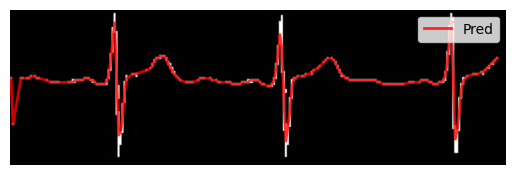

In [5]:
import matplotlib.pyplot as plt
plt.imshow(img_mask, cmap='gray', origin='lower')
plt.plot(predicted_x_clean, predicted_y_clean, color='red', linewidth=2, label='Pred', alpha=0.8)
plt.legend(loc='upper right')
            # plt.ylim([0, h])
            # plt.xlim([0, w])
plt.gca().invert_yaxis()
plt.axis('off')

#### extract gt

In [6]:
import wfdb
import pandas as pd
wfdb_root = "" # Fill with your own path
meta_csv = "" # Fill with your own path
meta = pd.read_csv(meta_csv, index_col=0)

H, W = img_mask.shape[:2]
print(W)
lead_map = {
        'I': 0, 'II': 1, 'III': 2,
        'aVR': 3, 'aVL': 4, 'aVF': 5,
        'V1': 6, 'V2': 7, 'V3': 8,
        'V4': 9, 'V5': 10, 'V6': 11
    }
parts = filename.split("_")
# print(parts[-1])
label = parts[-1]
label = label.replace(".jpg", "")

ecg_id = int(parts[1])
if ecg_id not in meta.index:
    raise RuntimeError("Missing ECG metadata", ecg_id)

record_name = meta.loc[ecg_id, "filename_hr"]
record = wfdb.rdrecord(os.path.join(wfdb_root, record_name))
if label == "rhythm":
    num_samples = 5000
    lead_idx = 1
else:
    num_samples = 1250
    lead_idx = lead_map[label]

signal = record.p_signal[:, lead_idx][:num_samples]

x_old = np.linspace(0, 1, len(signal))
signal_print = np.column_stack((x_old, signal))
print(signal_print)
x_new = np.linspace(0, 1, W)
signal = np.interp(x_new, x_old, signal)

sig_min = signal.min()
sig_max = signal.max()
signal = (signal - sig_min) / (sig_max - sig_min + 1e-8)


y = (1.0 - signal) * (H - 1)
# y = y.astype(np.int32)
print(len(y))

x = np.arange(W)

signal_points = np.column_stack((x, y))
# print(signal_points)



249
[[          0       0.005]
 [ 0.00080064       0.005]
 [  0.0016013       0.005]
 ...
 [     0.9984       0.235]
 [     0.9992       0.233]
 [          1        0.23]]
249


In [ ]:
gt_y_aligned = y.copy() 

(np.float64(-0.5),
 np.float64(248.5),
 np.float64(81.60729691640437),
 np.float64(-0.5))

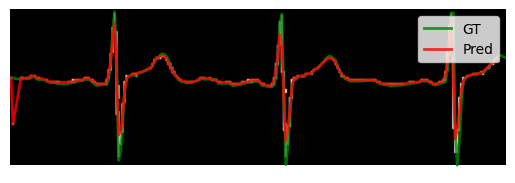

In [ ]:
y_gt = (1.0 - signal) * (H - 1)

pred_y = predicted_y_clean

pred_mean = np.mean(predicted_y_clean)
gt_mean = np.mean(y_gt)
y_gt_aligned = y_gt - (gt_mean - pred_mean)


# Plot with aligned GT
plt.imshow(img_mask, cmap='gray', origin='upper')
plt.plot(np.arange(W), y_gt_aligned, color='green', linewidth=2, label='GT', alpha=0.8)
plt.plot(predicted_x_clean, predicted_y_clean, color='red', linewidth=2, label='Pred', alpha=0.8)
plt.legend(loc='upper right')
plt.axis('off')

In [11]:
import os
import cv2
import matplotlib.pyplot as plt

def visualize_file_matplotlib(img_path, bbox_df, overlap_df):
    basename = os.path.basename(img_path).replace(".jpg", "")
    parts = basename.split("_")

    lead_name = parts[2].upper() if len(parts) >= 3 else "II"

    # Read image directly
    original = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    if original is None:
        raise FileNotFoundError(f"Cannot read image: {img_path}")
    h, w = original.shape[:2]

    # Get bbox row
    base = os.path.basename(img_path).split("_")[0] + ".jpg"
    try:
        bbox_df['index'] = bbox_df['index'].astype(int)
    except Exception:
        pass

    bbox_rows = bbox_df[(bbox_df['filename'] == base) & (bbox_df['index'] == int(parts[1]))]
    bbox_row = bbox_rows.iloc[0] if len(bbox_rows) > 0 else None

    df_ov = overlap_df[
        (overlap_df['filename'] == base) &
        ((overlap_df['lead1_idx'] == int(parts[1])) | (overlap_df['lead2_idx'] == int(parts[1])))
    ]

    # Draw overlays function
    def draw_overlays(ax):
        if bbox_row is None:
            return

        H, W = h, w
        ax.plot([0, W, W, 0, 0],
                [0, 0, H, H, 0],
                color='lime', linewidth=2)
        ax.text(0, -5, lead_name,
                color="lime", fontsize=10, weight='bold')

        full_x1 = int(bbox_row.x1)
        full_y1 = int(bbox_row.y1)

        for _, ov in df_ov.iterrows():
            ox1 = max(0, ov.overlap_x1 - full_x1)
            oy1 = max(0, ov.overlap_y1 - full_y1)
            ox2 = min(W, ov.overlap_x2 - full_x1)
            oy2 = min(H, ov.overlap_y2 - full_y1)

            if ox1 >= ox2 or oy1 >= oy2:
                continue

            partner = ov.lead2_label if ov.lead1_label == lead_name else ov.lead1_label

            ax.plot([ox1, ox2, ox2, ox1, ox1],
                    [oy1, oy1, oy2, oy2, oy1],
                    color='red', linewidth=2, linestyle='--')

            ax.text(ox1, oy1 - 5,
                    f"{lead_name} + {partner}",
                    color='red', fontsize=9, weight='bold')

    # --------- ONLY PLOT THE ORIGINAL IMAGE WITH BBOX ---------
    plt.figure(figsize=(7, 8))
    ax = plt.subplot(1, 1, 1)
    ax.imshow(original, cmap="gray")
    ax.set_title("Original Image with BBox Overlay")
    ax.axis("off")
    draw_overlays(ax)
    plt.tight_layout()
    plt.show()


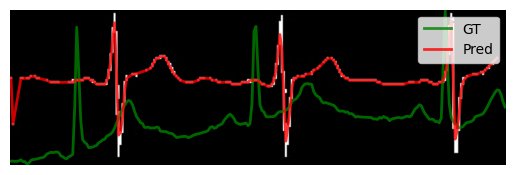

In [ ]:
import wfdb
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt

wfdb_root = "" # Fill with your own path
meta_csv = "" # Fill with your own path
meta = pd.read_csv(meta_csv, index_col=0)

H, W = img_mask.shape[:2]

lead_map = {
    'I': 0, 'II': 1, 'III': 2,
    'aVR': 3, 'aVL': 4, 'aVF': 5,
    'V1': 6, 'V2': 7, 'V3': 8,
    'V4': 9, 'V5': 10, 'V6': 11
}

parts = filename.split("_")
label = parts[-1].replace(".jpg", "")
ecg_id = int(parts[1])

record_name = meta.loc[ecg_id, "filename_hr"]
record = wfdb.rdrecord(os.path.join(wfdb_root, record_name))

if label == "rhythm":
    num_samples = 5000
    lead_idx = 1
else:
    num_samples = 1250
    lead_idx = lead_map[label]

signal_raw = record.p_signal[:, lead_idx][:num_samples]

x_old = np.linspace(0, 1, len(signal_raw))

if label == "rhythm":
    x_start = int(predicted_x_clean.min())
    x_end   = int(predicted_x_clean.max())
    W_sig = x_end - x_start + 1

    x_new = np.linspace(0, 1, W_sig)
    signal_interp = np.interp(x_new, x_old, signal_raw)

    signal = np.full(W, np.nan)
    signal[x_start:x_end + 1] = signal_interp
else:
    x_new = np.linspace(0, 1, W)
    signal = np.interp(x_new, x_old, signal_raw)

sig_min = np.nanmin(signal)
sig_max = np.nanmax(signal)
signal = (signal - sig_min) / (sig_max - sig_min + 1e-8)

y = (1.0 - signal) * (H - 1)
x = np.arange(W)

plt.imshow(img_mask, cmap='gray', origin='upper')

plt.plot(
    x,
    y,
    color='green',
    linewidth=2,
    label='GT',
    alpha=0.8
)

plt.plot(
    predicted_x_clean,
    predicted_y_clean,
    color='red',
    linewidth=2,
    label='Pred',
    alpha=0.8
)

plt.legend(loc='upper right')
plt.axis('off')
plt.show()


#### evaluation

In [ ]:
# Convert predicted predicted into full-width array
pred_y_aligned = np.full(W, np.nan)

x_pred = predicted_x_clean.astype(int)
pred_y_aligned[x_pred] = predicted_y_clean

In [51]:
valid_mask = np.isfinite(pred_y_aligned) & np.isfinite(gt_y_aligned)

pred_y = pred_y_aligned[valid_mask]
gt_y   = gt_y_aligned[valid_mask]

print("Valid points:", len(pred_y))


Valid points: 200


In [52]:
pixel_diff = pred_y - gt_y
abs_pixel_diff = np.abs(pixel_diff)

print("Mean pixel error:", abs_pixel_diff.mean())
print("Max pixel error:", abs_pixel_diff.max())
pixels_per_mv = 40.0

error_mv = pixel_diff / pixels_per_mv
abs_error_mv = np.abs(error_mv)



Mean pixel error: 1.5557370183480501
Max pixel error: 33.165024245456884


In [53]:
rmse_mv = np.sqrt(np.mean(error_mv ** 2))
print("RMSE (mV):", rmse_mv)


RMSE (mV): 0.10471467561257325


In [13]:
from scipy.stats import pearsonr

pcc, pcc_pvalue = pearsonr(pred_y, gt_y)

print("PCC:", pcc)


PCC: 0.7133956534465286


In [14]:
signal_power = np.mean(gt_y ** 2)
noise_power  = np.mean((pred_y - gt_y) ** 2)

snr_db = 10 * np.log10(signal_power / (noise_power + 1e-8))

print("SNR (dB):", snr_db)


SNR (dB): 17.458133536547212


### LOOP

In [10]:
from skimage.morphology import skeletonize
def extract_ecg(mask):
    mask_bin = (mask > 127).astype(np.uint8)
    skel = skeletonize(mask_bin).astype(np.uint8)
    ys, xs = np.where(skel == 1)
    points = np.column_stack((xs, ys))

    idx = np.argsort(points[:,0])
    return points[idx]

In [ ]:
from scipy.stats import pearsonr

pixels_per_mv = 40.0

def evaluate_single_mask(img_path, meta, wfdb_root):
    filename = os.path.basename(img_path)
    img_mask = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)

    if img_mask is None:
        return None

    H, W = img_mask.shape[:2]
    
    if img_mask.ndim == 3:
        img_mask = img_mask[:, :, 0]
    predicted_raw = extract_ecg(img_mask)
    
    predicted_x = predicted_raw[:, 0].astype(np.float32)
    predicted_y = predicted_raw[:, 1].astype(np.float32)

    mask = np.isfinite(predicted_x) & np.isfinite(predicted_y)
    predicted_x_clean = predicted_x[mask]
    predicted_y_clean = predicted_y[mask]
    
    sort_idx = np.argsort(predicted_x_clean)
    predicted_x_clean = predicted_x_clean[sort_idx]
    predicted_y_clean = predicted_y_clean[sort_idx]
        
    xs = predicted_x_clean
    ys = predicted_y_clean

    # Average y for same x
    x_unique = np.unique(xs)
    y_center = []
    
    for x in x_unique:
        y_center.append(np.mean(ys[xs == x]))

    predicted_x_clean = x_unique.astype(int)
    predicted_y_clean = np.array(y_center, dtype=np.float32)

    parts = filename.replace(".jpg", "").split("_")
    ecg_id = int(parts[1])
    label = parts[-1]

    if ecg_id not in meta.index:
        return None

    lead_map = {
        'I': 0, 'II': 1, 'III': 2,
        'aVR': 3, 'aVL': 4, 'aVF': 5,
        'V1': 6, 'V2': 7, 'V3': 8,
        'V4': 9, 'V5': 10, 'V6': 11
    }

    record_name = meta.loc[ecg_id, "filename_hr"]
    record = wfdb.rdrecord(os.path.join(wfdb_root, record_name))

    if label == "rhythm":
        signal = record.p_signal[:, 1][:5000]
    else:
        signal = record.p_signal[:, lead_map[label]][:1250]

    x_old = np.linspace(0, 1, len(signal))
    x_new = np.linspace(0, 1, W)
    signal = np.interp(x_new, x_old, signal)

    signal = (signal - signal.min()) / (signal.max() - signal.min() + 1e-8)
    gt_y = (1.0 - signal) * (H - 1)

    # gt_y_aligned = np.full(W, np.nan)

    # x_start = int(predicted_x_clean.min())
    # x_end = int(predicted_x_clean.max())

    # x_start = int(x_start)
    # x_end = int(x_end)

    # valid_len = x_end - x_start + 1
    # x_old = np.linspace(0, 1, len(gt_y))
    # x_new = np.linspace(0, 1, valid_len)
    # gt_visible = np.interp(x_new, x_old, gt_y)

    # gt_y_aligned[x_start:x_end+1] = gt_visible
    
    pred_y = predicted_y_clean
    pred_mean = np.mean(pred_y)
    gt_mean = np.mean(gt_y)
    gt_y_aligned = gt_y - (gt_mean - pred_mean)

    pred_y_aligned = np.full(W, np.nan)
    
    x_pred = predicted_x_clean.astype(int)
    pred_y_aligned[x_pred] = predicted_y_clean

    valid = np.isfinite(pred_y_aligned) & np.isfinite(gt_y_aligned)
    pred_y = pred_y_aligned[valid]
    gt_y   = gt_y_aligned[valid]

    # if len(pred_y) < 10:
    #     return None

    # Convert to mV
    gt_mv = gt_y / pixels_per_mv
    pred_mv = pred_y / pixels_per_mv

    error_mv = pred_mv - gt_mv
    rmse_mv = np.sqrt(np.mean(error_mv ** 2))

    pcc, _ = pearsonr(pred_mv, gt_mv)

    signal_power = np.sum(gt_mv ** 2)         # sum squared gt
    noise_power  = np.sum(error_mv ** 2)      # sum squared error
    snr_db = 10 * np.log10(signal_power / (noise_power + 1e-8))

    # error_mv = (pred_y - gt_y) / pixels_per_mv
    # rmse_mv = np.sqrt(np.mean(error_mv ** 2))

    # pcc, _ = pearsonr(pred_y, gt_y)
    
    

    # signal_power = np.mean(gt_y ** 2)
    # noise_power  = np.mean((pred_y - gt_y) ** 2)
    # snr_db = 10 * np.log10(signal_power / (noise_power + 1e-8))
    
    return {
        "filename": filename,
        "lead": label,
        "rmse_mv": rmse_mv,
        "pcc": pcc,
        "snr_db": snr_db
    }


In [16]:
import pandas as pd
import wfdb
wfdb_root = "" # Fill with your own path
meta_csv = "" # Fill with your own path

mask_folder = "" # Fill with your own path
output_folder = "" # Fill with your own path
csv_path = os.path.join(output_folder, "lasttt_normal_metrics.csv")

meta = pd.read_csv(meta_csv, index_col=0)
results = []
save_every = 100
counter = 0

if os.path.exists(csv_path):
    df_existing = pd.read_csv(csv_path)
    processed_files = set(df_existing["filename"].tolist())
    print(f"Resuming: {len(processed_files)} files already processed")
else:
    df_existing = pd.DataFrame()
    processed_files = set()
    print("From the start")

From the start


In [17]:
for fname in sorted(os.listdir(mask_folder)):
    if not fname.lower().endswith(".jpg"):
        continue

    if fname in processed_files:
        continue 

    img_path = os.path.join(mask_folder, fname)

    try:
        res = evaluate_single_mask(img_path, meta, wfdb_root)
        if res is not None:
            results.append(res)
            print(res)
            counter += 1
    except Exception as e:
        print("Error:", fname, e)
        
    if counter % save_every == 0 and results:
        df_new = pd.DataFrame(results)

        if os.path.exists(csv_path):
            df_new.to_csv(csv_path, mode="a", header=False, index=False)
        else:
            df_new.to_csv(csv_path, index=False)

        print(f"Saved checkpoint at {counter} new images")
        results= []
        
if results:
    pd.DataFrame(results).to_csv(csv_path, mode="a", header=False,index=False)
    print("Final save complete")

print("DONE")


{'filename': 'mask_18568_00_I.jpg', 'lead': 'I', 'rmse_mv': np.float64(0.048323827172314614), 'pcc': np.float64(0.8662936498101258), 'snr_db': np.float64(23.383076872413717)}
{'filename': 'mask_18568_01_II.jpg', 'lead': 'II', 'rmse_mv': np.float64(0.060560100271685235), 'pcc': np.float64(0.9396138236726823), 'snr_db': np.float64(23.935986061932383)}
{'filename': 'mask_18568_03_aVR.jpg', 'lead': 'aVR', 'rmse_mv': np.float64(0.04360732898422714), 'pcc': np.float64(0.9533053721481934), 'snr_db': np.float64(12.717893365838819)}
{'filename': 'mask_18568_04_aVL.jpg', 'lead': 'aVL', 'rmse_mv': np.float64(0.03119472867017375), 'pcc': np.float64(0.9017909537505039), 'snr_db': np.float64(20.72706166553068)}
{'filename': 'mask_18568_06_V1.jpg', 'lead': 'V1', 'rmse_mv': np.float64(0.04451205600207208), 'pcc': np.float64(0.9625707533187272), 'snr_db': np.float64(14.912451156498506)}
{'filename': 'mask_18568_07_V2.jpg', 'lead': 'V2', 'rmse_mv': np.float64(0.05711329215406688), 'pcc': np.float64(0.98

In [18]:
df = pd.read_csv(csv_path)
print(len(df))
print(df.head())

26533
                filename lead   rmse_mv       pcc     snr_db
0    mask_18568_00_I.jpg    I  0.048324  0.866294  23.383077
1   mask_18568_01_II.jpg   II  0.060560  0.939614  23.935986
2  mask_18568_03_aVR.jpg  aVR  0.043607  0.953305  12.717893
3  mask_18568_04_aVL.jpg  aVL  0.031195  0.901791  20.727062
4   mask_18568_06_V1.jpg   V1  0.044512  0.962571  14.912451


In [19]:
df[["rmse_mv", "pcc", "snr_db"]].describe()

,rmse_mv,pcc,snr_db
count,26533.000000,26533.000000,26533.000000
mean,0.066901,0.888815,20.251818
std,0.042128,0.160418,4.740633
min,0.013683,-0.145632,4.289368
25%,0.039016,0.876951,16.763673
50%,0.053939,0.931973,20.730885
75%,0.080602,0.963605,23.691291
max,0.527717,0.999165,38.664350


In [20]:
top_10_min = df.nsmallest(10, "snr_db")
print(top_10_min[['filename', 'snr_db']])

                          filename    snr_db
18877        mask_20899_02_III.jpg  4.289368
8801   mask_19636_12_II_rhythm.jpg  4.621441
370          mask_18626_02_III.jpg  4.737662
2032   mask_18833_12_II_rhythm.jpg  4.908115
6538          mask_19365_06_V1.jpg  5.458274
1493   mask_18763_12_II_rhythm.jpg  5.465513
9752   mask_19759_12_II_rhythm.jpg  5.769488
8301   mask_19577_12_II_rhythm.jpg  6.111874
11861  mask_20002_12_II_rhythm.jpg  6.128243
15052        mask_20407_02_III.jpg  6.278460


In [21]:
top_10_min = df.nsmallest(10, "pcc")
print(top_10_min[['filename', 'pcc']])

                          filename       pcc
2663   mask_18906_12_II_rhythm.jpg -0.145632
8343   mask_19582_12_II_rhythm.jpg -0.127036
24511  mask_21582_12_II_rhythm.jpg -0.121132
18865  mask_20897_12_II_rhythm.jpg -0.118680
9277   mask_19691_12_II_rhythm.jpg -0.117036
74     mask_18578_12_II_rhythm.jpg -0.114727
8238   mask_19570_12_II_rhythm.jpg -0.111961
22182  mask_21281_12_II_rhythm.jpg -0.109044
6861   mask_19404_12_II_rhythm.jpg -0.105687
21669  mask_21226_12_II_rhythm.jpg -0.098043


In [22]:
mean_per_lead = df.groupby("lead")[["rmse_mv", "pcc", "snr_db"]].mean()
print(mean_per_lead)

         rmse_mv       pcc     snr_db
lead                                 
I       0.057778  0.915162  23.017825
II      0.051708  0.927596  22.721414
III     0.056586  0.870862  16.079220
V1      0.047749  0.957588  17.100103
V2      0.075480  0.945760  18.689470
V3      0.083863  0.935800  20.073683
V4      0.103718  0.909880  21.802582
V5      0.095692  0.873783  22.472796
V6      0.070522  0.905473  23.720794
aVF     0.044374  0.909655  19.385817
aVL     0.040462  0.922157  22.278187
aVR     0.043088  0.944458  15.382868
rhythm  0.092585  0.630411  18.555067


In [23]:
without_rhythm = df[df["lead"] != "rhythm"]

print(without_rhythm.describe())


            rmse_mv           pcc        snr_db
count  23952.000000  23952.000000  23952.000000
mean       0.064133      0.916660     20.434655
std        0.039897      0.067995      4.695899
min        0.013683      0.522840      4.289368
25%        0.038399      0.888936     16.990606
50%        0.052425      0.936595     20.890521
75%        0.076592      0.965453     23.838143
max        0.527717      0.999165     38.664350


In [24]:
top_10_min = without_rhythm.nsmallest(10, "pcc")
print(top_10_min[['filename', 'pcc']])

                    filename       pcc
26213  mask_21797_02_III.jpg  0.522840
9704    mask_19753_11_V6.jpg  0.525103
4536    mask_19123_10_V5.jpg  0.528152
23861   mask_21488_10_V5.jpg  0.529180
25002   mask_21649_10_V5.jpg  0.532765
14506  mask_20337_02_III.jpg  0.536116
9334    mask_19700_10_V5.jpg  0.540518
13058  mask_20160_02_III.jpg  0.540837
19732   mask_20996_10_V5.jpg  0.540970
2596    mask_18898_09_V4.jpg  0.542980


In [25]:
top_10_min = df.nsmallest(10, "snr_db")
print(top_10_min[['filename', 'snr_db']])

                          filename    snr_db
18877        mask_20899_02_III.jpg  4.289368
8801   mask_19636_12_II_rhythm.jpg  4.621441
370          mask_18626_02_III.jpg  4.737662
2032   mask_18833_12_II_rhythm.jpg  4.908115
6538          mask_19365_06_V1.jpg  5.458274
1493   mask_18763_12_II_rhythm.jpg  5.465513
9752   mask_19759_12_II_rhythm.jpg  5.769488
8301   mask_19577_12_II_rhythm.jpg  6.111874
11861  mask_20002_12_II_rhythm.jpg  6.128243
15052        mask_20407_02_III.jpg  6.278460


In [26]:
top_10_max = df.nlargest(10, "snr_db")
print(top_10_max[['filename', 'snr_db']])

                    filename     snr_db
26466   mask_21827_09_V4.jpg  38.664350
24133   mask_21533_11_V6.jpg  36.360110
11566  mask_19969_02_III.jpg  35.590398
8026    mask_19544_10_V5.jpg  34.591766
4775   mask_19153_02_III.jpg  34.268388
16548  mask_20595_04_aVL.jpg  34.255809
2665    mask_18907_01_II.jpg  33.968904
22489   mask_21319_09_V4.jpg  33.847912
5007    mask_19181_06_V1.jpg  33.772852
7038    mask_19428_08_V3.jpg  33.508116


### LOOP OVERLAP

In [27]:
import pandas as pd
import wfdb
wfdb_root = "" # Fill with your own path
meta_csv = "" # Fill with your own path

mask_folder = "" # Fill with your own path
output_folder = "" # Fill with your own path
csv_path = os.path.join(output_folder, "lasttt_overlap_metrics.csv")

meta = pd.read_csv(meta_csv, index_col=0)
results = []
save_every = 100
counter = 0

if os.path.exists(csv_path):
    df_existing = pd.read_csv(csv_path)
    processed_files = set(df_existing["filename"].tolist())
    print(f"Resuming: {len(processed_files)} files already processed")
else:
    df_existing = pd.DataFrame()
    processed_files = set()
    print("From the start")

From the start


In [28]:
for fname in sorted(os.listdir(mask_folder)):
    if not fname.lower().endswith(".jpg"):
        continue

    if fname in processed_files:
        continue 

    img_path = os.path.join(mask_folder, fname)

    try:
        res = evaluate_single_mask(img_path, meta, wfdb_root)
        if res is not None:
            results.append(res)
            print(res)
            counter += 1
    except Exception as e:
        print("Error:", fname, e)
        
    if counter % save_every == 0 and results:
        df_new = pd.DataFrame(results)

        if os.path.exists(csv_path):
            df_new.to_csv(csv_path, mode="a", header=False, index=False)
        else:
            df_new.to_csv(csv_path, index=False)

        print(f"Saved checkpoint at {counter} new images")
        results= []
        
if results:
    pd.DataFrame(results).to_csv(csv_path, mode="a", header=False,index=False)
    print("Final save complete")

print("DONE")


{'filename': 'mask_18568_02_III.jpg', 'lead': 'III', 'rmse_mv': np.float64(0.03790459338683461), 'pcc': np.float64(0.9410442794373304), 'snr_db': np.float64(24.18685331509724)}
{'filename': 'mask_18568_05_aVF.jpg', 'lead': 'aVF', 'rmse_mv': np.float64(0.03218271448177513), 'pcc': np.float64(0.9726264882844905), 'snr_db': np.float64(27.448645431008206)}
{'filename': 'mask_18571_03_aVR.jpg', 'lead': 'aVR', 'rmse_mv': np.float64(0.02715922147177191), 'pcc': np.float64(0.9742156680516223), 'snr_db': np.float64(15.925597030070755)}
{'filename': 'mask_18571_06_V1.jpg', 'lead': 'V1', 'rmse_mv': np.float64(0.023150558997778594), 'pcc': np.float64(0.984030815430696), 'snr_db': np.float64(19.042199437713762)}
{'filename': 'mask_18573_01_II.jpg', 'lead': 'II', 'rmse_mv': np.float64(0.04912615136345934), 'pcc': np.float64(0.9378683458852497), 'snr_db': np.float64(22.684474735301393)}
{'filename': 'mask_18573_02_III.jpg', 'lead': 'III', 'rmse_mv': np.float64(0.04232571672890918), 'pcc': np.float64(

In [29]:
df = pd.read_csv(csv_path)
print(len(df))
print(df.head())

10925
                filename lead   rmse_mv       pcc     snr_db
0  mask_18568_02_III.jpg  III  0.037905  0.941044  24.186853
1  mask_18568_05_aVF.jpg  aVF  0.032183  0.972626  27.448645
2  mask_18571_03_aVR.jpg  aVR  0.027159  0.974216  15.925597
3   mask_18571_06_V1.jpg   V1  0.023151  0.984031  19.042199
4   mask_18573_01_II.jpg   II  0.049126  0.937868  22.684475


In [30]:
df[["rmse_mv", "pcc", "snr_db"]].describe()

,rmse_mv,pcc,snr_db
count,10925.000000,10925.000000,10925.000000
mean,0.097950,0.905866,19.564651
std,0.130553,0.117274,5.143569
min,0.012618,-0.126996,-0.064843
25%,0.037626,0.886363,15.938381
50%,0.055634,0.945452,19.658746
75%,0.098867,0.969791,23.374287
max,2.254606,0.998488,33.733792


In [31]:
top_10_min = df.nsmallest(10, "snr_db")
print(top_10_min[['filename', 'snr_db']])

                   filename    snr_db
7800   mask_20919_08_V3.jpg -0.064843
8574   mask_21155_08_V3.jpg  1.405589
2727   mask_19413_08_V3.jpg  1.407147
9379   mask_21378_10_V5.jpg  1.530238
10049  mask_21567_10_V5.jpg  1.990773
5795   mask_20345_08_V3.jpg  2.232840
4949   mask_20088_07_V2.jpg  2.552042
10682  mask_21757_09_V4.jpg  2.814591
4903   mask_20078_07_V2.jpg  2.815158
7594   mask_20862_10_V5.jpg  3.064475


In [32]:
top_10_min = df.nsmallest(10, "pcc")
print(top_10_min[['filename', 'pcc']])

                          filename       pcc
3193         mask_19551_02_III.jpg -0.126996
6921   mask_20675_12_II_rhythm.jpg -0.119530
391    mask_18712_12_II_rhythm.jpg -0.033481
6759   mask_20628_12_II_rhythm.jpg -0.033056
6418   mask_20517_12_II_rhythm.jpg -0.029698
10159         mask_21598_10_V5.jpg -0.021420
9808   mask_21489_12_II_rhythm.jpg -0.017780
1111   mask_18916_12_II_rhythm.jpg -0.015250
2715   mask_19407_12_II_rhythm.jpg -0.014320
3912   mask_19762_12_II_rhythm.jpg -0.003867


In [33]:
mean_per_lead = df.groupby("lead")[["rmse_mv", "pcc", "snr_db"]].mean()
print(mean_per_lead)

         rmse_mv       pcc     snr_db
lead                                 
I       0.052414  0.866456  20.874300
II      0.060454  0.896266  21.145294
III     0.068910  0.843945  17.037022
V1      0.064225  0.951577  16.749613
V2      0.143439  0.923950  17.271901
V3      0.158950  0.909642  18.444341
V4      0.165139  0.898226  20.898650
V5      0.192021  0.838243  21.751002
V6      0.072512  0.939397  24.946107
aVF     0.043472  0.921019  20.990241
aVL     0.041998  0.936690  23.633419
aVR     0.042208  0.941909  15.905360
rhythm  0.125598  0.718190  18.903513


In [34]:
without_rhythm = df[df["lead"] != "rhythm"]

print(without_rhythm.describe())


            rmse_mv           pcc        snr_db
count  10624.000000  10624.000000  10624.000000
mean       0.097167      0.911183     19.583382
std        0.131484      0.103441      5.156246
min        0.012618     -0.126996     -0.064843
25%        0.037334      0.889383     15.928288
50%        0.054916      0.946603     19.653384
75%        0.096140      0.970117     23.414318
max        2.254606      0.998488     33.733792


In [35]:
top_10_min = without_rhythm.nsmallest(10, "pcc")
print(top_10_min[['filename', 'pcc']])

                    filename       pcc
3193   mask_19551_02_III.jpg -0.126996
10159   mask_21598_10_V5.jpg -0.021420
2727    mask_19413_08_V3.jpg  0.020327
5696    mask_20314_10_V5.jpg  0.034983
2497    mask_19356_10_V5.jpg  0.036716
4538    mask_19962_10_V5.jpg  0.041731
1530    mask_19043_10_V5.jpg  0.072338
10049   mask_21567_10_V5.jpg  0.072364
2794    mask_19434_10_V5.jpg  0.072987
7550    mask_20852_10_V5.jpg  0.078954


In [36]:
top_10_min = df.nsmallest(10, "snr_db")
print(top_10_min[['filename', 'snr_db']])

                   filename    snr_db
7800   mask_20919_08_V3.jpg -0.064843
8574   mask_21155_08_V3.jpg  1.405589
2727   mask_19413_08_V3.jpg  1.407147
9379   mask_21378_10_V5.jpg  1.530238
10049  mask_21567_10_V5.jpg  1.990773
5795   mask_20345_08_V3.jpg  2.232840
4949   mask_20088_07_V2.jpg  2.552042
10682  mask_21757_09_V4.jpg  2.814591
4903   mask_20078_07_V2.jpg  2.815158
7594   mask_20862_10_V5.jpg  3.064475


In [37]:
top_10_max = df.nlargest(10, "snr_db")
print(top_10_max[['filename', 'snr_db']])

                    filename     snr_db
10884  mask_21827_05_aVF.jpg  33.733792
1211    mask_18945_01_II.jpg  33.728472
6884    mask_20664_11_V6.jpg  33.684360
660    mask_18793_04_aVL.jpg  33.144503
7541    mask_20849_10_V5.jpg  33.114455
3266    mask_19567_11_V6.jpg  33.035732
1215   mask_18945_05_aVF.jpg  33.016607
9118   mask_21319_05_aVF.jpg  32.754592
7774    mask_20911_11_V6.jpg  32.602138
3686    mask_19699_11_V6.jpg  32.596557


In [38]:
median_snr = df['snr_db'].median()
top_10_median = df.iloc[(df['snr_db'] - median_snr).abs().argsort()[:20]]

print(top_10_median[['filename', 'snr_db']].describe)

<bound method NDFrame.describe of                           filename     snr_db
28           mask_18588_04_aVL.jpg  19.658746
40            mask_18593_06_V1.jpg  19.658738
4324   mask_19894_12_II_rhythm.jpg  19.660527
7524          mask_20845_06_V1.jpg  19.661507
6365          mask_20502_07_V2.jpg  19.662004
2640          mask_19390_01_II.jpg  19.654552
4824          mask_20050_07_V2.jpg  19.654208
6526         mask_20549_05_aVF.jpg  19.664469
7940         mask_20961_03_aVR.jpg  19.652559
3546          mask_19659_08_V3.jpg  19.665236
1129          mask_18921_07_V2.jpg  19.665446
10359         mask_21662_06_V1.jpg  19.651250
10256        mask_21631_05_aVF.jpg  19.666335
1712          mask_19104_08_V3.jpg  19.649830
9143         mask_21324_02_III.jpg  19.668455
1230          mask_18949_09_V4.jpg  19.648629
8666          mask_21188_06_V1.jpg  19.647836
8704         mask_21202_05_aVF.jpg  19.669929
6020         mask_20402_05_aVF.jpg  19.644356
7861          mask_20936_06_V1.jpg  19.674171>